# 05 · Results figures
Reads the training logs in `logs/` and writes presentation-quality figures to `figures/`.
Every number comes from the logs, nothing is typed in by hand.
Run from the repo root or from `notebooks/`.

In [10]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LOGS, FIGS = ROOT / "logs", ROOT / "figures"
FIGS.mkdir(exist_ok=True)

# name -> (log file, colour, parameters in millions)
RUNS = {
    "GRU":                 ("rnn_12000_training_log.txt",       "#2a9d8f", 44.3),
    "Transformer lr 1e-3": ("tf_12000_training_log.txt",        "#e9c46a", 21.7),
    "Transformer lr 2e-3": ("tf_12000_lr2e-3_training_log.txt", "#e76f51", 21.7),
}
OFFICIAL_PER = 10.1   # official pretrained GRU, 120k batches, batch size 64 (from the official repo)
FOOTER = "Brain-to-Text '25 validation set · greedy CTC phoneme decoding, no language model · batch size 32, T4, float32"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220, "font.size": 12,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.labelsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.facecolor": "#fcfcfd",
    "legend.frameon": False, "legend.fontsize": 11,
})

## Parse the logs

In [11]:
VAL = re.compile(r"Val batch (\d+): PER \(avg\): ([\d.]+) CTC Loss \(avg\): ([\d.]+)")
SESS = re.compile(r"(t15\.\d{4}\.\d{2}\.\d{2}) val PER: ([\d.]+)")
TRAIN = re.compile(r"Train batch (\d+): loss: ([\d.]+) grad norm: ([\d.]+)")


def parse_log(path):
    train, val, sess, step = [], [], [], None
    with open(path, errors="ignore") as f:
        for line in f:
            if (m := VAL.search(line)):
                step = int(m[1])
                val.append((step, float(m[2]), float(m[3])))
            elif (m := SESS.search(line)) and step is not None:
                sess.append((step, m[1], float(m[2])))
            elif (m := TRAIN.search(line)):
                train.append((int(m[1]), float(m[2]), float(m[3])))
    out = dict(
        train=pd.DataFrame(train, columns=["batch", "loss", "grad"]),
        val=pd.DataFrame(val, columns=["batch", "per", "ctc"]),
        sess=pd.DataFrame(sess, columns=["batch", "session", "per"]),
    )
    assert all(len(v) for v in out.values()), f"nothing parsed from {path}"
    return out


data = {}
for name, (fn, _, _) in RUNS.items():
    p = LOGS / fn
    if p.exists():
        data[name] = parse_log(p)
    else:
        print("missing:", p)

rows = []
for name, d in data.items():
    v = d["val"][d["val"].batch > 0]
    b = v.loc[v.per.idxmin()]
    d["best_batch"] = int(b.batch)
    rows.append(dict(run=name, best_val_PER_pct=round(b.per * 100, 2),
                     at_batch=int(b.batch), params_M=RUNS[name][2]))
summary = pd.DataFrame(rows).sort_values("best_val_PER_pct")
print(summary.to_string(index=False))

                run  best_val_PER_pct  at_batch  params_M
                GRU             13.43     11999      44.3
Transformer lr 2e-3             41.79     11999      21.7
Transformer lr 1e-3             52.61     10800      21.7


## Figure functions

In [12]:
def plot_curves(ax):
    for name, d in data.items():
        v = d["val"][d["val"].batch > 0]
        col = RUNS[name][1]
        ax.plot(v.batch, v.per * 100, marker="o", ms=5, lw=2.4, color=col, label=name)
        ax.annotate(f"{v.per.iloc[-1] * 100:.1f}%", (v.batch.iloc[-1], v.per.iloc[-1] * 100),
                    xytext=(8, 0), textcoords="offset points", va="center",
                    color=col, fontweight="bold")
    ax.axhline(OFFICIAL_PER, ls="--", lw=1.2, color="#666")
    ax.text(ax.get_xlim()[0] + 150, OFFICIAL_PER + 1.5,
            f"official GRU, 120k batches: {OFFICIAL_PER}%", color="#666", fontsize=10)
    ax.set_ylim(0, 85)
    ax.set_xlabel("training batch")
    ax.set_ylabel("validation PER")
    ax.yaxis.set_major_formatter(PercentFormatter())
    ax.set_title("Validation phoneme error rate during training")
    ax.legend(loc="upper right")


def plot_loss(ax):
    for name, d in data.items():
        t = d["train"][d["train"].batch >= 200]
        ax.plot(t.batch, t.loss.rolling(5, min_periods=1).mean(), lw=2.2,
                color=RUNS[name][1], label=name)
    ax.set_yscale("log")
    ax.set_xlabel("training batch")
    ax.set_ylabel("training CTC loss (smoothed)")
    ax.set_title("Training loss: the transformer is still underfitting")
    ax.legend(loc="upper right")


def plot_bars(ax):
    s = summary.sort_values("best_val_PER_pct", ascending=False)
    ax.barh(s.run, s.best_val_PER_pct, color=[RUNS[r][1] for r in s.run], height=0.6)
    for y, (per, pm) in enumerate(zip(s.best_val_PER_pct, s.params_M)):
        ax.text(per + 0.8, y, f"{per:.2f}%  ·  {pm:.1f}M params", va="center", fontweight="bold")
    ax.axvline(OFFICIAL_PER, ls="--", lw=1.2, color="#666")
    ax.set_xlim(0, s.best_val_PER_pct.max() * 1.5)
    ax.xaxis.set_major_formatter(PercentFormatter())
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("best validation PER (lower is better)")
    ax.set_title("Best validation PER by model")


def session_table():
    tfs = [n for n in data if n.startswith("Transformer")]
    best = summary.set_index("run").best_val_PER_pct
    tf = min(tfs, key=lambda n: best[n])
    g, t = data["GRU"], data[tf]
    a = g["sess"][g["sess"].batch == g["best_batch"]].set_index("session").per * 100
    b = t["sess"][t["sess"].batch == t["best_batch"]].set_index("session").per * 100
    return tf, pd.concat([a.rename("gru"), b.rename("tf")], axis=1).dropna().sort_index()


TF_BEST, SESS_DF = session_table()


def plot_scatter(ax):
    df = SESS_DF
    lim = max(df.gru.max(), df.tf.max()) * 1.05
    ax.plot([0, lim], [0, lim], ls="--", color="#777", lw=1.2)
    ax.scatter(df.gru, df.tf, s=60, color=RUNS[TF_BEST][1], edgecolor="white", lw=0.9, zorder=3)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel("GRU PER on that session")
    ax.set_ylabel(f"{TF_BEST} PER on that session")
    ax.xaxis.set_major_formatter(PercentFormatter())
    ax.yaxis.set_major_formatter(PercentFormatter())
    ax.text(lim * 0.97, lim * 0.04, "above the line = transformer worse", color="#666", fontsize=10, ha="right")
    ax.set_title(f"Per-session PER ({len(df)} sessions)")


def plot_timeline(ax):
    df = SESS_DF
    x = np.arange(len(df))
    ax.plot(x, df.gru, lw=2.2, marker="o", ms=4, color=RUNS["GRU"][1], label="GRU")
    ax.plot(x, df.tf, lw=2.2, marker="o", ms=4, color=RUNS[TF_BEST][1], label=TF_BEST)
    ax.fill_between(x, df.gru, df.tf, color="#999", alpha=0.15)
    step = max(1, len(df) // 8)
    ax.set_xticks(x[::step])
    ax.set_xticklabels(df.index.str[4:][::step], rotation=30, ha="right")
    ax.yaxis.set_major_formatter(PercentFormatter())
    ax.set_ylabel("validation PER")
    ax.set_title("Per-session PER over the recording period")
    ax.legend(loc="upper left")

## Render and save

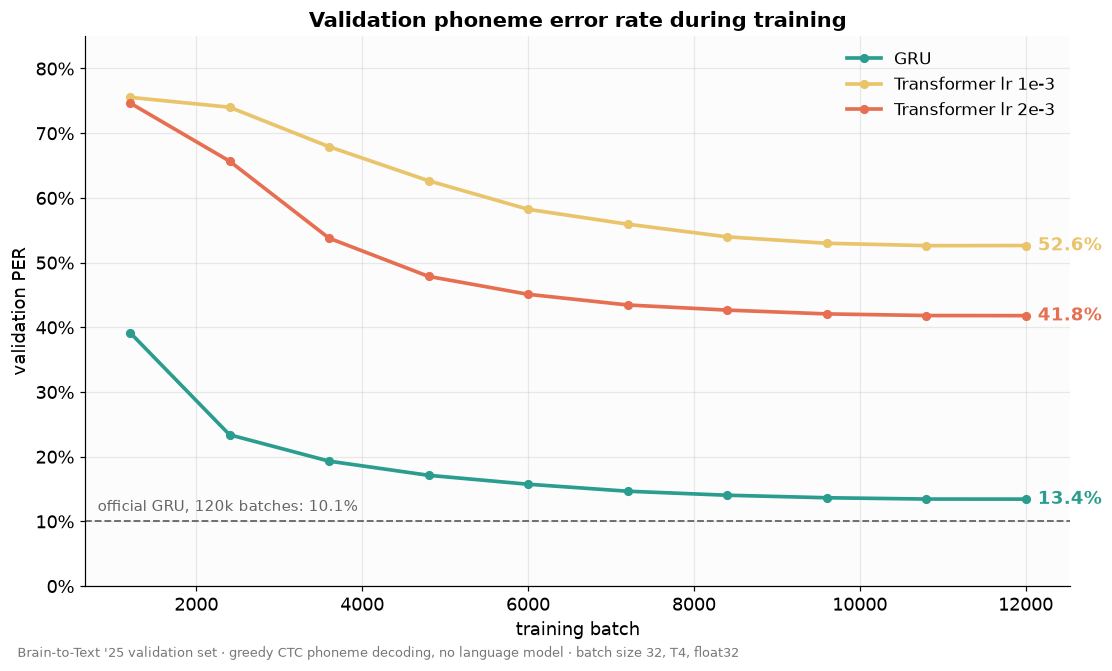

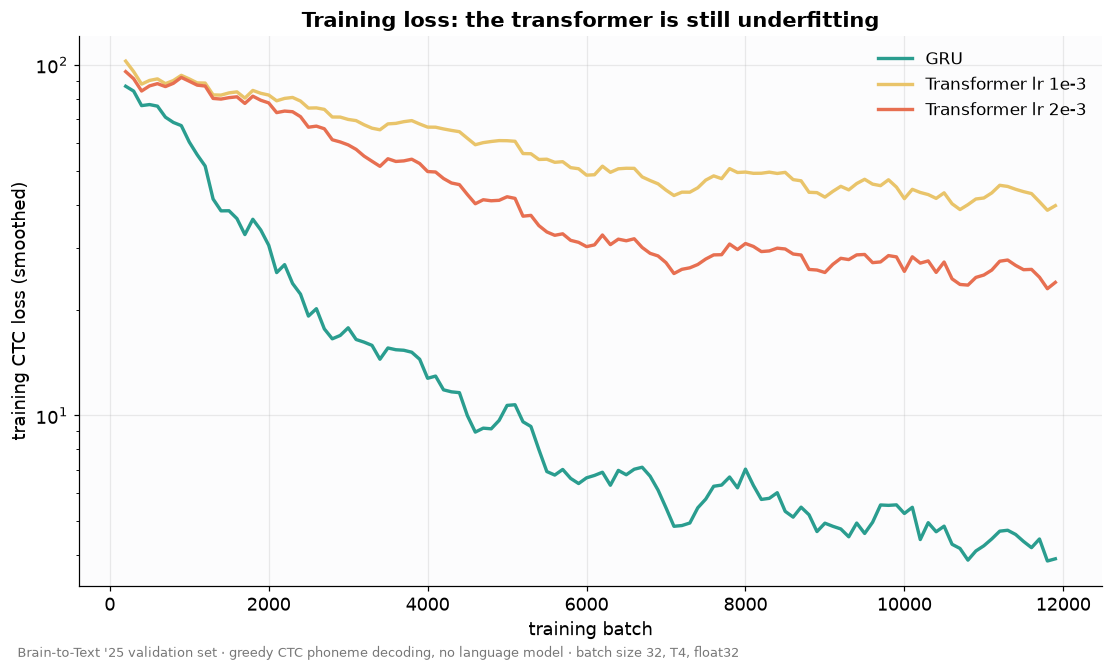

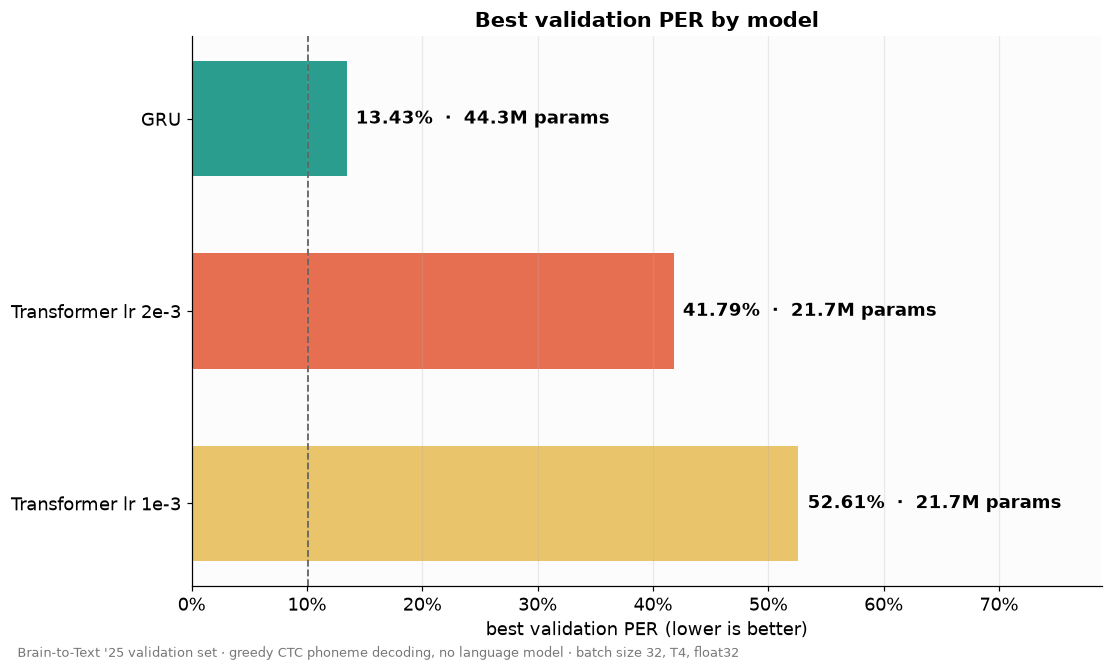

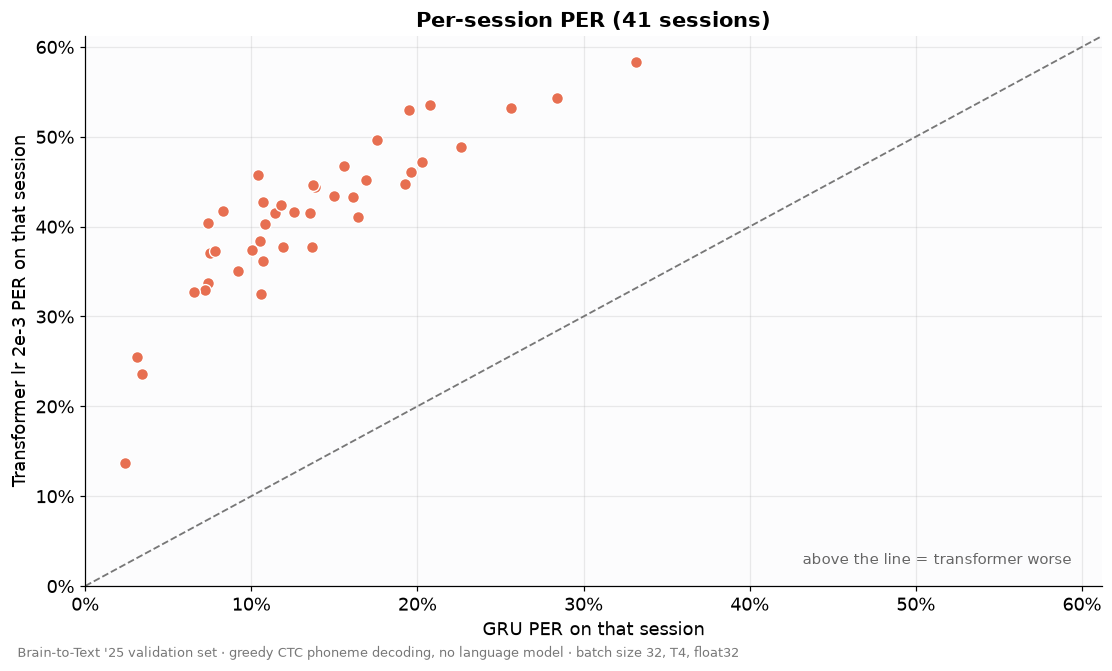

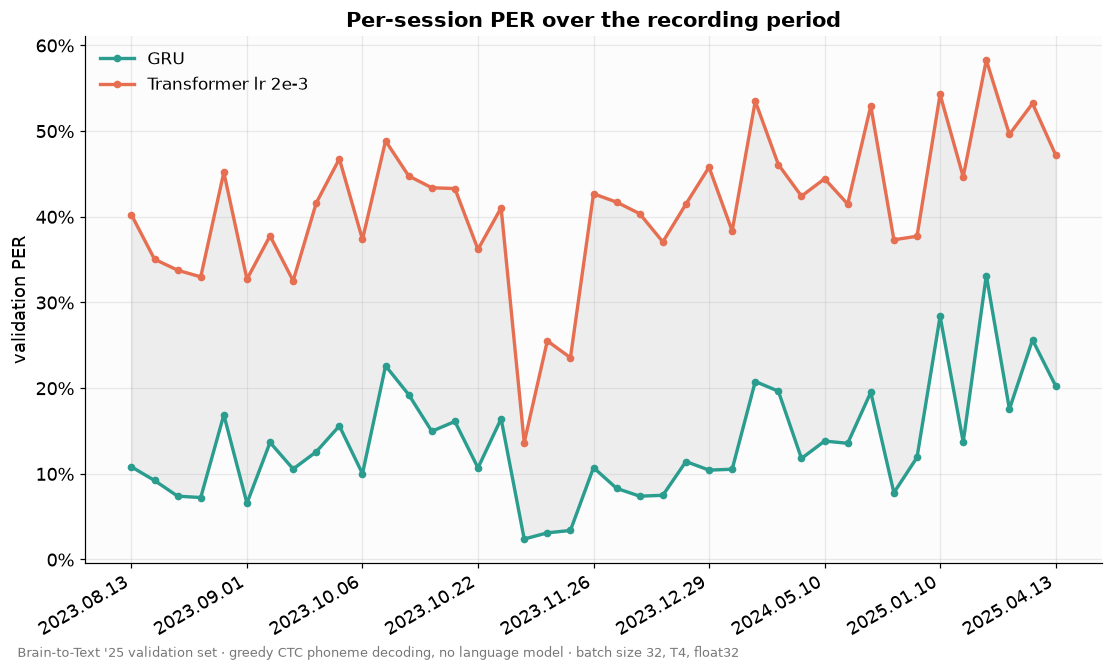

In [13]:
PLOTS = {
    "01_val_per_curves": plot_curves,
    "02_training_loss": plot_loss,
    "03_best_per_by_model": plot_bars,
    "04_per_session_scatter": plot_scatter,
    "05_per_session_timeline": plot_timeline,
}
for name, fn in PLOTS.items():
    fig, ax = plt.subplots(figsize=(10, 5.8), constrained_layout=True)
    fn(ax)
    fig.text(0.01, -0.02, FOOTER, fontsize=8.5, color="#777")
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

## Hero figure (all four panels, for the README and slides)

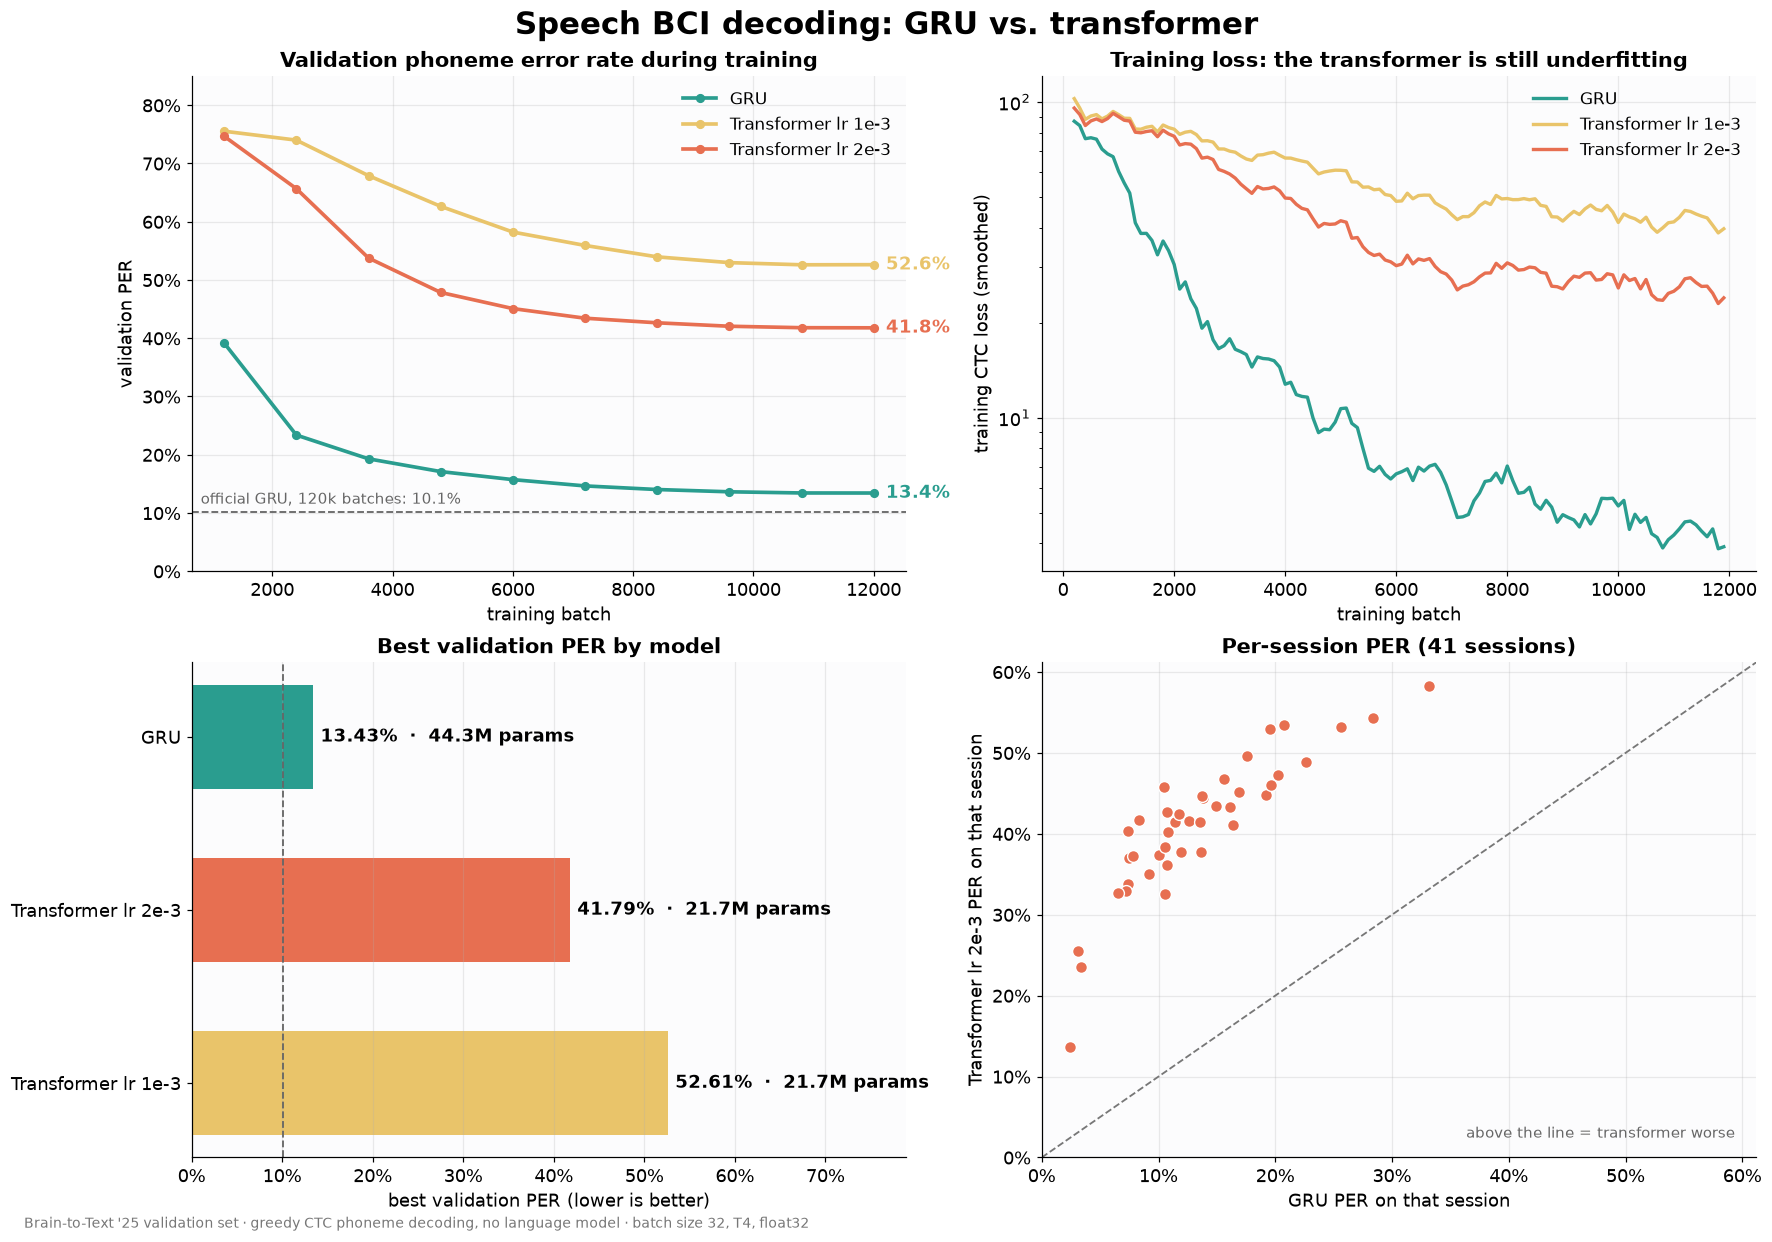

In [14]:
fig, axs = plt.subplots(2, 2, figsize=(16, 11), constrained_layout=True)
plot_curves(axs[0, 0])
plot_loss(axs[0, 1])
plot_bars(axs[1, 0])
plot_scatter(axs[1, 1])
fig.suptitle("Speech BCI decoding: GRU vs. transformer", fontsize=20, fontweight="bold")
fig.text(0.01, -0.01, FOOTER, fontsize=9, color="#777")
fig.savefig(FIGS / "00_hero.png", bbox_inches="tight", facecolor="white")
plt.show()

## Numbers for `results.md`

In [15]:
print(summary.to_string(index=False))
print("\nfigures written:", sorted(p.name for p in FIGS.glob("*.png")))

                run  best_val_PER_pct  at_batch  params_M
                GRU             13.43     11999      44.3
Transformer lr 2e-3             41.79     11999      21.7
Transformer lr 1e-3             52.61     10800      21.7

figures written: ['00_hero.png', '01_val_per_curves.png', '02_training_loss.png', '03_best_per_by_model.png', '04_per_session_scatter.png', '05_per_session_timeline.png']
